# Tema 7 · Generalizar: sobreajuste, validación y regularización

Un modelo sirve si acierta en datos que nunca vio.

Este cuaderno es el tema 7 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/ruta/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/ruta/7-generalizar-sobreajuste-validacion-y-regularizacion/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

Dos estudiantes se preparan para el mismo examen con la misma lista de 50 problemas resueltos. Una se aprende de memoria las 50 respuestas. El otro entiende cómo se resuelve cada tipo de problema. Si el examen trae exactamente esos 50 problemas, a los dos les va perfecto. Pero el examen trae problemas **nuevos**. ¿A quién le va mejor?

Con los modelos pasa lo mismo. En el tema 6 mediste el error del modelo de diabetes con los mismos pacientes con que lo entrenaste, y avisamos que eso era hacerse trampa: es corregir el examen con las preguntas que el modelo ya vio resueltas. Un modelo sirve si acierta en datos que **nunca vio**. A eso se le llama **generalizar**, y este tema trata de cómo medirlo y cómo lograrlo.

En este tema vas a:

- dividir los datos en **entrenamiento**, **validación** y **prueba**, y saber para qué sirve cada parte;
- reconocer el **subajuste** y el **sobreajuste** en las curvas de error;
- aplicar la **validación cruzada k-fold** para elegir un modelo sin depender de la suerte de una sola división;
- usar **Ridge** (L2) y **Lasso** (L1), y explicar por qué Lasso deja coeficientes exactamente en cero.

Necesitas lo del tema 6: el modelo ŷ = w·x + b, el MSE, la interfaz `fit` y `predict` de scikit-learn y la estandarización.

## Actividad: ¿memoriza o aprende?

Los puntos llenos son los datos de **entrenamiento**: con ellos se ajusta la curva. Los puntos huecos son datos de **validación**: salen de la misma regla, pero el modelo no los ve al entrenar. La curva es un **polinomio**: con grado 1 es una recta, con grado 2 una parábola, y con grados más altos puede doblarse más veces. Las dos barras miden el error (el MSE) con cada grupo de puntos.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/ruta/7-generalizar-sobreajuste-validacion-y-regularizacion/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Empieza en grado 1. ¿La recta sigue la forma de los puntos? ¿Las dos barras son altas o bajas?
2. Sube el grado de a uno hasta 15. Mira la barra de entrenamiento: ¿alguna vez sube? Mira la de validación: ¿qué hace al principio y qué hace al final?
3. Con grado 15, pulsa «Nuevos datos» varias veces. Las curvas claras son los ajustes con los datos anteriores. ¿Cuánto cambia la curva de un sorteo a otro? Haz lo mismo con grado 3.
4. Deja el grado en 15 y sube λ (lambda) poco a poco. ¿Qué le pasa a la curva y a la barra de validación? ¿Y si subes λ al máximo?
5. Activa «Ver la regla verdadera». ¿Qué grado y qué λ la imitan mejor?

Acabas de ver la idea central del tema: **que un modelo se equivoque poco con los datos que vio no prueba que haya aprendido; puede haberlos memorizado**. El error que importa es el de los datos nuevos, y hay dos perillas para controlarlo: la complejidad del modelo (el grado) y la regularización (λ).

## Datos de una regla conocida

Como en el tema 6, empezamos con datos **sintéticos**: los fabricamos con una regla conocida, una onda *y* = sen(*x*), más un ruido al azar. Así podemos comparar lo que aprende el modelo con la verdad.

Y desde el principio, antes de entrenar nada, **separamos los datos en tres grupos**:

| Grupo | Para qué sirve | Cuándo se usa |
|---|---|---|
| **Entrenamiento** | Ajustar los parámetros del modelo (con `fit`) | Siempre que se entrena |
| **Validación** | Comparar modelos y elegir sus perillas (el grado, λ) | Muchas veces, mientras se decide |
| **Prueba** | Estimar cómo le irá al modelo elegido con datos nuevos | **Una sola vez**, al final |

`train_test_split` de scikit-learn mezcla los datos al azar y los parte en dos. Lo usamos dos veces: primero apartamos la prueba, y del resto sacamos la validación. Su argumento `random_state` es la semilla de la mezcla: con la misma semilla, la misma división.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Semilla fija: cada vez que corras esto saldrán los mismos datos
rng = np.random.default_rng(1)
n = 40
x = rng.uniform(-3, 3, size=n)
# La regla «secreta»: una onda, más un ruido que nadie puede predecir
y = np.sin(x) + rng.normal(0, 0.3, size=n)
X = x.reshape(-1, 1)                  # scikit-learn quiere una tabla

# Primero se aparta la prueba (10 puntos): no se toca hasta el final
X_resto, X_prueba, y_resto, y_prueba = train_test_split(
    X, y, test_size=10, random_state=0)
# Del resto, 10 puntos para validación y 20 para entrenar
X_ent, X_val, y_ent, y_val = train_test_split(
    X_resto, y_resto, test_size=10, random_state=0)

print("Entrenamiento:", len(X_ent), "  validación:", len(X_val),
      "  prueba:", len(X_prueba))

Entrenamiento: 20   validación: 10   prueba: 10


¿Por qué tres grupos y no dos? Porque cada vez que miras el error de validación para decidir algo, ese grupo deja de ser del todo «nuevo»: lo estás usando para elegir. Si eliges entre muchos modelos, alguno va a tener suerte con esos diez puntos. La prueba queda guardada para el final, para tener una medida honesta del modelo que elegiste.

## Polinomios: una perilla de complejidad

Una recta no puede seguir una onda. Para doblar la curva usamos un **polinomio** de grado *g*:

$$\hat{y} = {w}_{1} x + {w}_{2} {x}^{2} + \cdots + {w}_{g} {x}^{g} + b$$

El truco es que esto **sigue siendo una regresión lineal**, aunque la curva no sea una recta. Se llama lineal porque cada peso *w* multiplica una columna y todo se suma; no importa que las columnas sean *x*², *x*³… Basta con inventar columnas nuevas, *x*², *x*³, …, y dárselas a `LinearRegression` como si fueran características distintas. `PolynomialFeatures` hace exactamente eso:

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Las potencias de x, de 1 a 3, para x = 2 y x = 3
potencias = PolynomialFeatures(degree=3, include_bias=False)
print(potencias.fit_transform([[2], [3]]))

[[ 2.  4.  8.]
 [ 3.  9. 27.]]


Con *x* = 3 y grado 15, la última columna vale 3¹⁵, más de 14 millones, mientras que la primera vale 3. Columnas con escalas tan distintas son un problema: lo viste en el tema 6 con el valle alargado, y aquí además hacen inexactas las cuentas de la computadora. Por eso, después de calcular las potencias, las **estandarizamos** con `StandardScaler` (media 0 y desviación 1, como en los temas 5 y 6).

Para no repetir los tres pasos cada vez, los encadenamos con `make_pipeline`. El resultado se usa como cualquier modelo: `fit` calcula las potencias, aprende la media y la desviación de cada columna **con los datos de entrenamiento** y ajusta la regresión; `predict` aplica los mismos pasos a datos nuevos. (En el tema 10 vas a ver los *pipelines* con más detalle.)

Grado  1:  MSE entrenamiento = 0.232   MSE validación = 0.292
Grado  3:  MSE entrenamiento = 0.037   MSE validación = 0.029
Grado  9:  MSE entrenamiento = 0.031   MSE validación = 0.059
Grado 15:  MSE entrenamiento = 0.014   MSE validación = 1.253


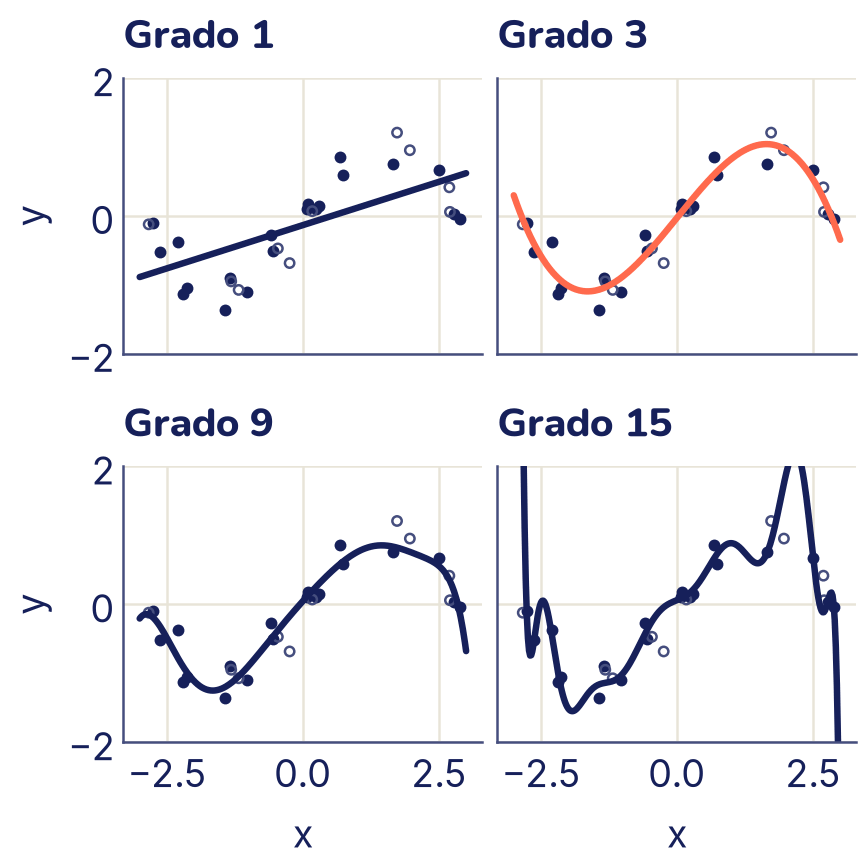

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

def polinomio(grado):
    """Regresión polinomial: potencias de x, estandarizar, recta."""
    return make_pipeline(PolynomialFeatures(grado, include_bias=False),
                         StandardScaler(), LinearRegression())

# Una cuadrícula fina de x para dibujar las curvas
x_dib = np.linspace(-3, 3, 300).reshape(-1, 1)

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8),
                         sharex=True, sharey=True)
for eje, grado in zip(ejes.flat, [1, 3, 9, 15]):
    modelo = polinomio(grado).fit(X_ent, y_ent)
    e_ent = mean_squared_error(y_ent, modelo.predict(X_ent))
    e_val = mean_squared_error(y_val, modelo.predict(X_val))
    print(f"Grado {grado:2d}:  MSE entrenamiento = {e_ent:.3f}"
          f"   MSE validación = {e_val:.3f}")
    # Solo el grado que mejor generaliza va resaltado (color "C1")
    color = "C1" if grado == 3 else "C0"
    eje.scatter(X_ent, y_ent, s=14, color="C0")
    eje.scatter(X_val, y_val, s=14, facecolors="none", edgecolors="C2")
    eje.plot(x_dib, modelo.predict(x_dib), color=color)
    eje.set_title(f"Grado {grado}")
    eje.set_ylim(-2, 2)
for eje in ejes[1]:
    eje.set_xlabel("x")
for eje in ejes[:, 0]:
    eje.set_ylabel("y")
plt.show()

Los números y los dibujos cuentan la misma historia:

- **Grado 1, subajuste.** La recta es demasiado simple para una onda. Se equivoca mucho con los dos grupos de puntos: no le alcanza ni para los datos que vio. Se dice que el modelo tiene **sesgo** alto (ojo: es otro sentido de la palabra, no el intercepto *b* del tema 6; aquí «sesgo» es un error sistemático por usar un modelo demasiado rígido).
- **Grado 3, buen ajuste.** Sigue la forma de la onda y se equivoca parecido con los puntos que vio y con los nuevos.
- **Grado 15, sobreajuste.** Tiene el error más chico con los puntos de entrenamiento, pero el más grande con los de validación. Se retorció para pasar cerca de cada punto lleno, incluido su ruido. **Memorizó** en lugar de aprender la forma.

## La curva en forma de U

Probemos todos los grados del 1 al 15 y guardemos los dos errores:

Grado con menor error de validación: 3
Grado  1:  entrenamiento 0.232   validación 0.292
Grado  3:  entrenamiento 0.037   validación 0.029
Grado  6:  entrenamiento 0.031   validación 0.054
Grado 12:  entrenamiento 0.016   validación 0.951
Grado 15:  entrenamiento 0.014   validación 1.253


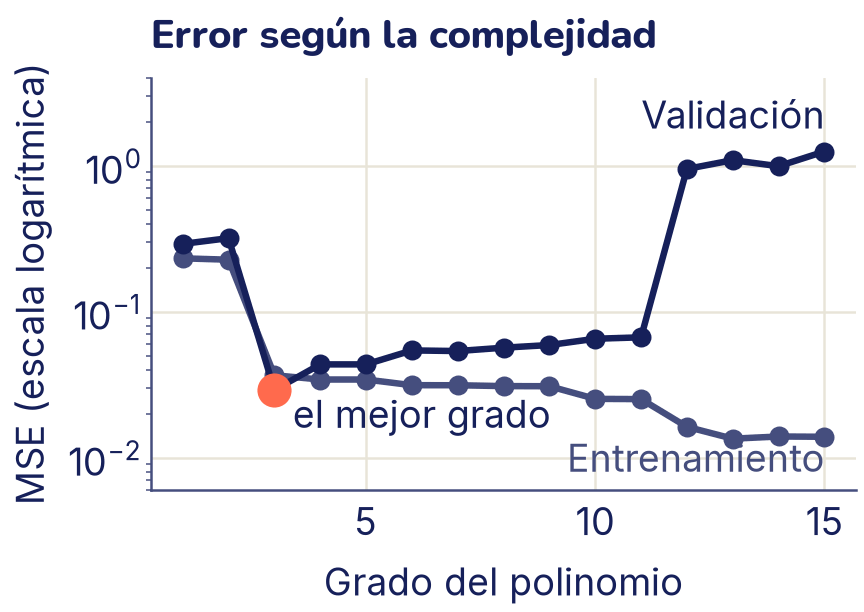

In [ ]:
grados = range(1, 16)
err_ent, err_val = [], []
for grado in grados:
    modelo = polinomio(grado).fit(X_ent, y_ent)
    err_ent.append(mean_squared_error(y_ent, modelo.predict(X_ent)))
    err_val.append(mean_squared_error(y_val, modelo.predict(X_val)))

mejor = grados[np.argmin(err_val)]
print("Grado con menor error de validación:", mejor)
for grado in [1, 3, 6, 12, 15]:
    print(f"Grado {grado:2d}:  entrenamiento {err_ent[grado - 1]:.3f}"
          f"   validación {err_val[grado - 1]:.3f}")

plt.plot(grados, err_ent, color="C2", marker="o")
plt.plot(grados, err_val, color="C0", marker="o")
plt.scatter([mejor], [min(err_val)], color="C1", s=160, zorder=3)
plt.yscale("log")
plt.ylim(0.006, 4)
# Nombres escritos junto a cada curva, en lugar de una leyenda
plt.text(15, 1.8, "Validación", ha="right")
plt.text(15, 0.008, "Entrenamiento", ha="right", color="C2")
plt.text(3.4, 0.016, "el mejor grado")
plt.xlabel("Grado del polinomio")
plt.ylabel("MSE (escala logarítmica)")
plt.title("Error según la complejidad")
plt.show()

Esta es la figura más importante del tema. Fíjate en tres cosas:

1. **El error de entrenamiento casi no deja de bajar.** Cada grado nuevo agrega una perilla, y con más perillas siempre se puede pasar igual o más cerca de los puntos que se ven. Por eso el error de entrenamiento no sirve para elegir el grado: siempre elegiría el más alto.
2. **El error de validación forma una U.** A la izquierda, el modelo es demasiado simple (subajuste). A la derecha, es tan flexible que memoriza el ruido (sobreajuste). El fondo de la U es el mejor equilibrio.
3. **La distancia entre las dos curvas** es el síntoma del sobreajuste. Si el error de entrenamiento es mucho menor que el de validación, el modelo se está aprendiendo los datos de memoria.

Una **curva de validación** es justamente esto: el error de entrenamiento y el de validación frente a una perilla del modelo. scikit-learn la calcula con `validation_curve`; aquí la programamos con un bucle para ver cada paso.

## Sesgo y varianza

El botón «Nuevos datos» de la actividad mostraba otra cara del sobreajuste: el modelo de grado 15 cambiaba muchísimo de un sorteo de datos a otro. Midámoslo. Vamos a sacar 200 muestras distintas de 20 puntos de la misma regla, a entrenar con cada una y a mirar qué predice cada modelo en *x* = 2, donde la verdad es sen(2) ≈ 0,91.

In [ ]:
def nuevos_datos(semilla, n=20):
    """Otra muestra de la misma regla: sen(x) más ruido."""
    r = np.random.default_rng(semilla)
    x_n = r.uniform(-3, 3, size=n)
    return x_n.reshape(-1, 1), np.sin(x_n) + r.normal(0, 0.3, size=n)

x0 = [[2.0]]                          # el punto donde miramos
for grado in [1, 3, 15]:
    preds = []
    for semilla in range(200):
        X_n, y_n = nuevos_datos(semilla)
        modelo = polinomio(grado).fit(X_n, y_n)
        preds.append(modelo.predict(x0)[0])
    preds = np.array(preds)
    print(f"Grado {grado:2d}:  mediana {np.median(preds):5.2f}"
          f"   la mitad central entre {np.percentile(preds, 25):5.2f}"
          f" y {np.percentile(preds, 75):5.2f}")

Grado  1:  mediana  0.69   la mitad central entre  0.57 y  0.81
Grado  3:  mediana  0.98   la mitad central entre  0.89 y  1.04
Grado 15:  mediana  0.95   la mitad central entre  0.54 y  1.29


Usamos la mediana y la «mitad central» (del primer cuartil al tercero, Q1 y Q3, como en las cajas del tema 4) en lugar de la media y la desviación estándar, porque unas pocas predicciones del grado 15 son tan disparatadas que arruinarían el promedio. En el código, `np.percentile(preds, 25)` da el valor que deja por debajo al 25 % de las predicciones (eso es Q1), y `np.percentile(preds, 75)`, el que deja por debajo al 75 % (Q3). Esos números muestran las dos formas de equivocarse:

- **Sesgo**: el grado 1 se equivoca de forma sistemática. Sea cual sea la muestra, predice algo lejos de 0,91: una recta no puede imitar una onda. Más datos no lo arreglan.
- **Varianza**: el grado 15 tiene la mediana cerca de la verdad, pero cada muestra lo lleva a un lugar distinto. Su predicción depende tanto de los puntos que le tocaron que no se puede confiar en ninguna en particular.
- El grado 3 tiene poco de los dos.

Un modelo demasiado simple tiene **sesgo alto**; uno demasiado flexible para la cantidad de datos que tiene, **varianza alta**. Bajar uno suele subir el otro: es el **equilibrio entre sesgo y varianza**, y el fondo de la U es donde está mejor repartido. Más datos ayudan con la varianza (lo verás en la curva de aprendizaje); el sesgo solo se arregla con un modelo más flexible.

## Validación cruzada k-fold

Nuestro conjunto de validación tiene solo 10 puntos. Si la división al azar hubiera sido otra, el error de validación habría salido distinto, y quizás hasta otro grado ganador. Veámoslo con el grado 3 y cinco semillas de división:

In [ ]:
for semilla in range(5):
    Xe, Xv, ye, yv = train_test_split(X_resto, y_resto, test_size=10,
                                      random_state=semilla)
    modelo = polinomio(3).fit(Xe, ye)
    print(f"random_state={semilla}:  MSE de validación = "
          f"{mean_squared_error(yv, modelo.predict(Xv)):.3f}")

random_state=0:  MSE de validación = 0.029
random_state=1:  MSE de validación = 0.061
random_state=2:  MSE de validación = 0.055
random_state=3:  MSE de validación = 0.027
random_state=4:  MSE de validación = 0.047


El mismo modelo, con los mismos datos, recibe una nota u otra según la suerte de la división: la peor es más del doble de la mejor. La **validación cruzada k-fold** reparte esa suerte:

1. Se parten los datos (sin la prueba) en *k* grupos del mismo tamaño, llamados **pliegues** (en inglés, *folds*).
2. Se entrena *k* veces: cada vez, un grupo distinto hace de validación y los otros *k* − 1 de entrenamiento.
3. Se promedian los *k* errores de validación.

Así **cada punto se usa una vez para validar** y el resultado ya no depende de una sola división. Lo más común es *k* = 5 o *k* = 10. El precio es entrenar *k* veces.

`KFold` define los grupos (con `shuffle=True` los mezcla antes, con su propia semilla) y `cross_val_score` hace todo el ciclo. Por una convención de scikit-learn, siempre **maximiza** sus puntajes, así que el MSE viene con el signo cambiado: `"neg_mean_squared_error"`. Le volvemos a cambiar el signo para leerlo.

In [ ]:
from sklearn.model_selection import KFold, cross_val_score

cinco = KFold(n_splits=5, shuffle=True, random_state=0)

resultados = []
for grado in grados:
    puntajes = cross_val_score(polinomio(grado), X_resto, y_resto,
                               cv=cinco, scoring="neg_mean_squared_error")
    resultados.append(-puntajes.mean())     # el MSE, con su signo

grado_cv = grados[np.argmin(resultados)]
for grado in [1, 2, 3, 4, 8, 15]:
    print(f"Grado {grado:2d}:  MSE de validación cruzada = "
          f"{resultados[grado - 1]:.3f}")
print("Grado elegido por validación cruzada:", grado_cv)

Grado  1:  MSE de validación cruzada = 0.296
Grado  2:  MSE de validación cruzada = 0.307
Grado  3:  MSE de validación cruzada = 0.045
Grado  4:  MSE de validación cruzada = 0.048
Grado  8:  MSE de validación cruzada = 0.069
Grado 15:  MSE de validación cruzada = 20.008
Grado elegido por validación cruzada: 3


La validación cruzada usó los 30 puntos que no son de prueba, en cinco rondas de 24 para entrenar y 6 para validar. Elige el grado 3, el mismo que eligió nuestra validación de 10 puntos, pero ahora con más respaldo.

Recién ahora, con el grado decidido, **usamos la prueba, una sola vez**. Entrenamos el modelo elegido con todos los datos que no son de prueba y medimos:

In [ ]:
final = polinomio(grado_cv).fit(X_resto, y_resto)
error_prueba = mean_squared_error(y_prueba, final.predict(X_prueba))
print(f"Grado {grado_cv}, MSE con los datos de prueba: {error_prueba:.3f}")
# El MSE de la regla verdadera, sen(x), con estos mismos 10 puntos
print(f"MSE de sen(x) con los datos de prueba: "
      f"{mean_squared_error(y_prueba, np.sin(X_prueba[:, 0])):.3f}")

Grado 3, MSE con los datos de prueba: 0.044
MSE de sen(x) con los datos de prueba: 0.055


Para comparar, calculamos también el error de la regla verdadera, sen(*x*), que conocemos solo porque fabricamos los datos. Ni ella llega a cero: el ruido no se puede predecir. Como el ruido tiene una desviación de 0,3, ningún modelo puede bajar, en promedio y con muchos datos nuevos, de un MSE de 0,3² = 0,09. Ese piso se llama **error irreducible**. Aquí los dos números salieron por debajo de 0,09, y el polinomio hasta le ganó por poco a la regla verdadera: con solo diez puntos de prueba, también hay suerte. Lo que sí dicen es que el grado 3 se equivoca con datos nuevos tanto como la verdad misma, que es lo mejor que se puede pedir.

## Regularización: castigar los pesos grandes

Elegir un grado bajo es una forma de evitar el sobreajuste. Hay otra que permite usar un modelo flexible sin que se descontrole: la **regularización**. La idea es cambiar lo que el entrenamiento minimiza. Además de equivocarse poco, le pedimos al modelo que **sus pesos sean chicos**:

$$\text{pérdida} = \text{MSE} + \lambda \sum_{j = 1}^{d} {w}_{j}^{2}$$

Esto se llama **Ridge** o **regularización L2** (por la suma de cuadrados de los pesos). El número *λ* (lambda) dice cuánto pesa el castigo: con *λ* = 0 es la regresión de siempre; con *λ* muy grande, lo más barato es dejar todos los pesos casi en cero, y la curva se vuelve casi plana. El intercepto *b* no se castiga: solo mueve la curva arriba o abajo y no la hace más retorcida.

¿Por qué pesos chicos dan curvas más suaves? La curva de grado 15 sin regularizar logra pasar cerca de cada punto sumando potencias con pesos enormes, de signos opuestos, que casi se cancelan; donde dejan de cancelarse, la curva se dispara. Con el castigo, esos pesos enormes salen caros.

En scikit-learn el modelo se llama `Ridge` y *λ* se llama `alpha`. (scikit-learn escribe la pérdida con constantes un poco distintas, así que el valor de `alpha` no es exactamente el mismo *λ*; la idea es la misma.)

alpha =   0.001:  entrenamiento 0.028   validación 0.058
alpha =    0.01:  entrenamiento 0.031   validación 0.051
alpha =     0.1:  entrenamiento 0.034   validación 0.047
alpha =       1:  entrenamiento 0.068   validación 0.096
alpha =      10:  entrenamiento 0.192   validación 0.263
alpha =     100:  entrenamiento 0.352   validación 0.467


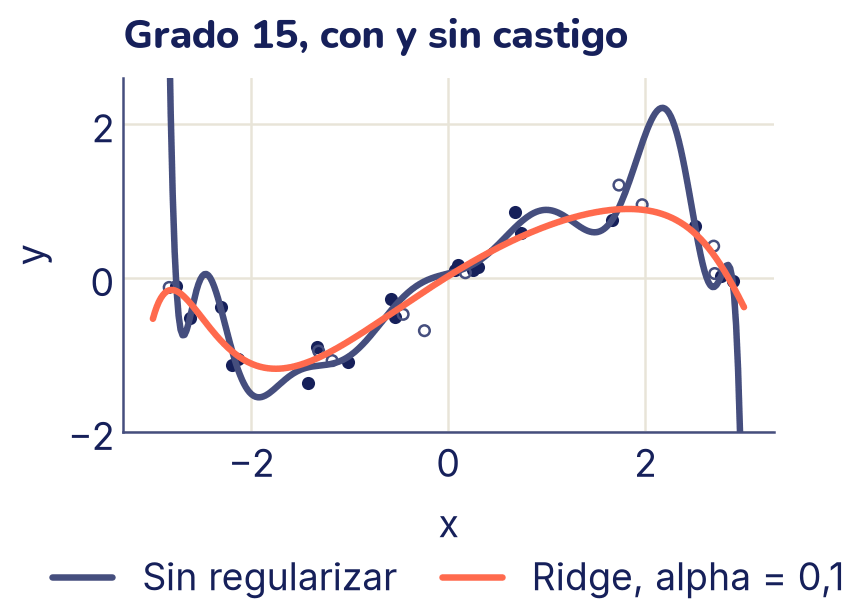

In [ ]:
from sklearn.linear_model import Ridge

def polinomio_ridge(grado, alpha):
    """Como polinomio(), pero con Ridge en lugar de LinearRegression."""
    return make_pipeline(PolynomialFeatures(grado, include_bias=False),
                         StandardScaler(), Ridge(alpha=alpha))

for alpha in [0.001, 0.01, 0.1, 1, 10, 100]:
    modelo = polinomio_ridge(15, alpha).fit(X_ent, y_ent)
    e_ent = mean_squared_error(y_ent, modelo.predict(X_ent))
    e_val = mean_squared_error(y_val, modelo.predict(X_val))
    print(f"alpha = {alpha:7}:  entrenamiento {e_ent:.3f}"
          f"   validación {e_val:.3f}")

sin_reg = polinomio(15).fit(X_ent, y_ent)
con_reg = polinomio_ridge(15, 0.1).fit(X_ent, y_ent)
plt.scatter(X_ent, y_ent, s=18, color="C0")
plt.scatter(X_val, y_val, s=18, facecolors="none", edgecolors="C2")
plt.plot(x_dib, sin_reg.predict(x_dib), color="C2",
         label="Sin regularizar")
plt.plot(x_dib, con_reg.predict(x_dib), color="C1",
         label="Ridge, alpha = 0,1")
plt.ylim(-2, 2.6)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Grado 15, con y sin castigo")
# La leyenda va debajo del gráfico, para no tapar las curvas
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2,
           frameon=False, handlelength=1.6, columnspacing=1.2)
plt.show()

Con el mismo grado 15, Ridge da una curva suave. *λ* es otra perilla de complejidad, como el grado, pero continua: con `alpha` muy chico vuelve el sobreajuste; con `alpha` muy grande, el subajuste. Su valor también se elige con validación (o validación cruzada), nunca con la prueba.

## Ridge y Lasso con datos reales

Volvamos al conjunto de diabetes del tema 6: 442 pacientes y 10 características. Vamos a ver qué les pasa a los 10 pesos a medida que sube `alpha`. Primero estandarizamos las columnas, y esto no es un detalle: **el castigo trata a todos los pesos por igual**, así que las columnas tienen que estar en la misma escala. Si una columna estuviera en metros y otra en milímetros, el castigo apretaría mucho más a una que a otra sin ninguna razón.

Pesos con alpha = 1000: [ 1.6 -1.7  9.9  6.8  1.1  0.  -5.5  4.8  8.7  4.6]


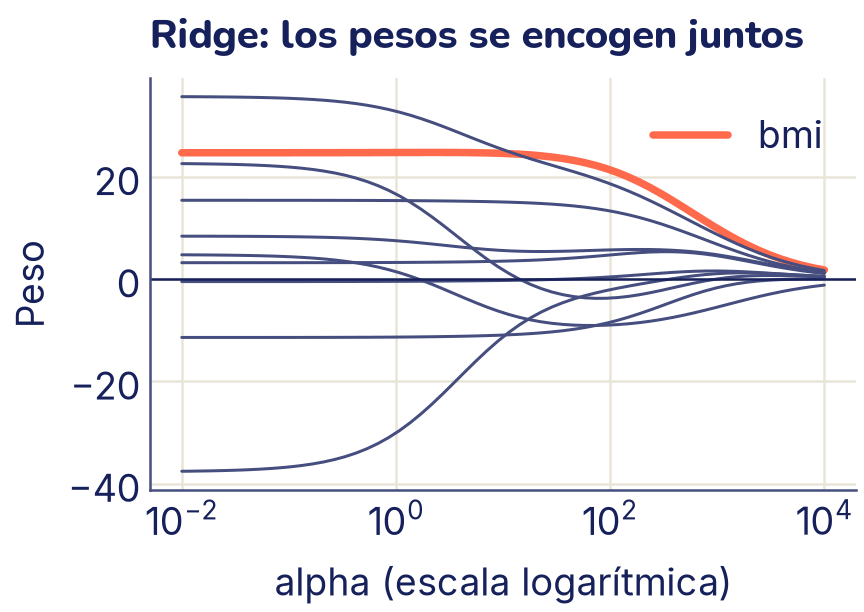

In [ ]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True)
nombres = list(diabetes.data.columns)
X_d = StandardScaler().fit_transform(diabetes.data)
y_d = diabetes.target.to_numpy()

alphas_r = np.logspace(-2, 4, 60)     # de 0,01 a 10 000
pesos_r = np.array([Ridge(alpha=a).fit(X_d, y_d).coef_ for a in alphas_r])

for i, nombre in enumerate(nombres):
    # Solo bmi va resaltado (color "C1"); las otras nueve, en "C2"
    if nombre == "bmi":
        plt.plot(alphas_r, pesos_r[:, i], color="C1", linewidth=3,
                 label="bmi")
    else:
        plt.plot(alphas_r, pesos_r[:, i], color="C2", linewidth=1.2)
plt.axhline(0, color="C0", linewidth=1)
plt.xscale("log")
plt.xlabel("alpha (escala logarítmica)")
plt.ylabel("Peso")
plt.title("Ridge: los pesos se encogen juntos")
plt.legend()
plt.show()

print("Pesos con alpha = 1000:",
      np.round(Ridge(alpha=1000).fit(X_d, y_d).coef_, 1))

Con Ridge, todos los pesos se van encogiendo hacia cero, pero ninguno llega exactamente a cero. Ahora cambiemos una sola cosa del castigo: en lugar de los pesos al cuadrado, sus **valores absolutos**.

$$\text{pérdida} = \text{MSE} + \lambda \sum_{j = 1}^{d} | {w}_{j} |$$

Esto es **Lasso**, o **regularización L1**. Parece un cambio menor, pero el resultado es muy distinto:

alpha =  0.1:  9 pesos distintos de cero: age, sex, bmi, bp, s1, s2, s4, s5, s6
alpha =    1:  7 pesos distintos de cero: sex, bmi, bp, s1, s3, s5, s6
alpha =    5:  5 pesos distintos de cero: sex, bmi, bp, s3, s5
alpha =   20:  3 pesos distintos de cero: bmi, bp, s5


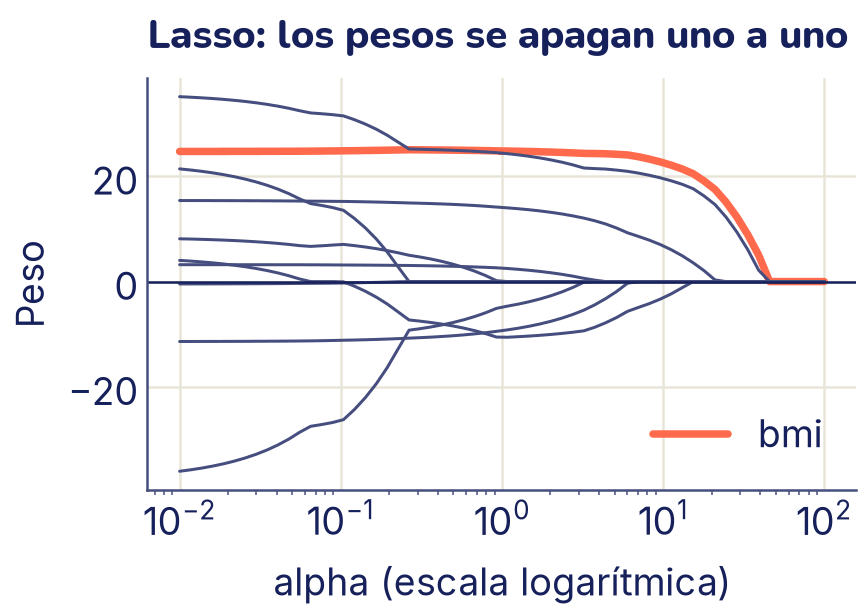

In [ ]:
from sklearn.linear_model import Lasso

alphas_l = np.logspace(-2, 2, 60)     # de 0,01 a 100
pesos_l = np.array([Lasso(alpha=a).fit(X_d, y_d).coef_ for a in alphas_l])

for i, nombre in enumerate(nombres):
    if nombre == "bmi":
        plt.plot(alphas_l, pesos_l[:, i], color="C1", linewidth=3,
                 label="bmi")
    else:
        plt.plot(alphas_l, pesos_l[:, i], color="C2", linewidth=1.2)
plt.axhline(0, color="C0", linewidth=1)
plt.xscale("log")
plt.xlabel("alpha (escala logarítmica)")
plt.ylabel("Peso")
plt.title("Lasso: los pesos se apagan uno a uno")
plt.legend()
plt.show()

for alpha in [0.1, 1, 5, 20]:
    lasso = Lasso(alpha=alpha).fit(X_d, y_d)
    vivos = [n for n, w in zip(nombres, lasso.coef_) if w != 0]
    print(f"alpha = {alpha:4}:  {len(vivos)} pesos distintos de cero:",
          ", ".join(vivos))

Con Lasso, los pesos no solo se encogen: **se apagan**, uno por uno, y quedan exactamente en cero. Un peso en cero significa que el modelo ya no usa esa característica. Por eso Lasso sirve también para **elegir variables**: con `alpha` grande, se queda solo con las que más ayudan a predecir. Aquí, las últimas en sobrevivir son `bmi` (índice de masa corporal) y `s5` (un análisis de sangre).

## ¿Por qué Lasso deja pesos en cero?

Hay una forma geométrica de verlo, con un modelo de solo dos pesos, *w*₁ y *w*₂. Minimizar «MSE + *λ* · castigo» es parecido a minimizar el MSE **con un presupuesto**: los pesos no pueden salir de una región alrededor del origen. La intuición: con un *λ* grande, cada unidad de peso cuesta caro, y el modelo se conforma con pesos chicos, como si tuviera poco presupuesto para gastar en ellos. Cuanto más grande *λ*, más chica la región. Para Ridge, la región es un **círculo** (*w*₁² + *w*₂² no puede pasar de cierto valor). Para Lasso, es un **rombo** (|*w*₁| + |*w*₂| tampoco).

El MSE, como viste en el tema 6, forma un valle con curvas de nivel en forma de elipse. La solución es el punto de la región donde el valle está más bajo: donde la región toca a la primera elipse. Probémoslo con una pérdida inventada cuyo mínimo está en (2, 1), fuera de las dos regiones. Para cada región recorremos 4000 puntos de su borde y nos quedamos con el de menor pérdida:

Ridge (círculo): w1 = 0.97   w2 = 0.24
Lasso (rombo):   w1 = 1.00   w2 = 0.00


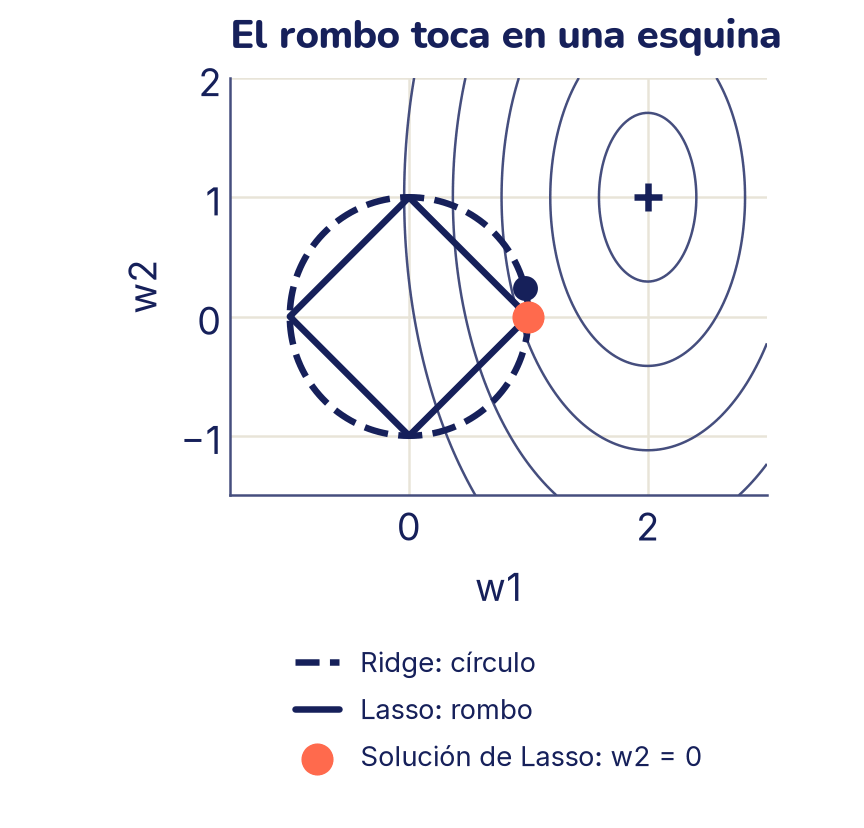

In [ ]:
def perdida(w1, w2):
    """Un valle con el mínimo en (2, 1), más empinado en w1."""
    return 3 * (w1 - 2) ** 2 + (w2 - 1) ** 2

t = np.linspace(0, 2 * np.pi, 4000)
# El borde del círculo de radio 1 y el del rombo |w1| + |w2| = 1
circulo = np.cos(t), np.sin(t)
rombo = (np.cos(t) / (np.abs(np.cos(t)) + np.abs(np.sin(t))),
         np.sin(t) / (np.abs(np.cos(t)) + np.abs(np.sin(t))))

i_c = np.argmin(perdida(*circulo))
i_r = np.argmin(perdida(*rombo))
print(f"Ridge (círculo): w1 = {circulo[0][i_c]:.2f}"
      f"   w2 = {circulo[1][i_c]:.2f}")
print(f"Lasso (rombo):   w1 = {rombo[0][i_r]:.2f}"
      f"   w2 = {rombo[1][i_r]:.2f}")

W1, W2 = np.meshgrid(np.linspace(-1.5, 3, 200), np.linspace(-1.5, 2, 200))
# Una figura más alta, para que quepa la leyenda debajo
plt.figure(figsize=(4.8, 4.6))
plt.contour(W1, W2, perdida(W1, W2), levels=[0.5, 2, 4.5, 8, 12.5],
            colors="C2", linewidths=1)
plt.plot(*circulo, color="C0", linestyle="--", label="Ridge: círculo")
plt.plot(*rombo, color="C0", label="Lasso: rombo")
plt.scatter([circulo[0][i_c]], [circulo[1][i_c]], color="C0", s=80,
            zorder=3)
plt.scatter([rombo[0][i_r]], [rombo[1][i_r]], color="C1", s=140,
            zorder=4, label="Solución de Lasso: w2 = 0")
plt.scatter([2], [1], color="C0", marker="+", s=120)
plt.gca().set_aspect("equal")
plt.ylim(-1.5, 2)
plt.xlabel("w1")
plt.ylabel("w2")
plt.title("El rombo toca en una esquina")
# La leyenda va debajo del gráfico, para no tapar las elipses
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), fontsize=11,
           frameon=False, handlelength=1.6)
plt.show()

El círculo es redondo: la elipse lo toca en un punto cualquiera de su borde, donde los dos pesos suelen ser distintos de cero; solo se achican. El rombo, en cambio, tiene **esquinas** sobre los ejes, y las esquinas sobresalen: es muy probable que la elipse toque primero una esquina. En una esquina, uno de los pesos vale exactamente cero. Con muchas características, el «rombo» tiene muchísimas esquinas y aristas, y por eso Lasso apaga varios pesos a la vez.

## Curva de aprendizaje: ¿más datos ayudarían?

Una última herramienta de diagnóstico. La **curva de aprendizaje** muestra el error de entrenamiento y el de validación según **cuántos datos** se usan para entrenar. `learning_curve` de scikit-learn la calcula con validación cruzada: para cada tamaño, entrena con esa cantidad de pacientes y valida con los demás.

 15 pacientes:  entrenamiento   1120   validación  10954
 20 pacientes:  entrenamiento   1412   validación   6822
 30 pacientes:  entrenamiento   1882   validación   3921
 50 pacientes:  entrenamiento   2347   validación   3266
100 pacientes:  entrenamiento   2549   validación   3317
200 pacientes:  entrenamiento   2701   validación   3124
353 pacientes:  entrenamiento   2843   validación   2978


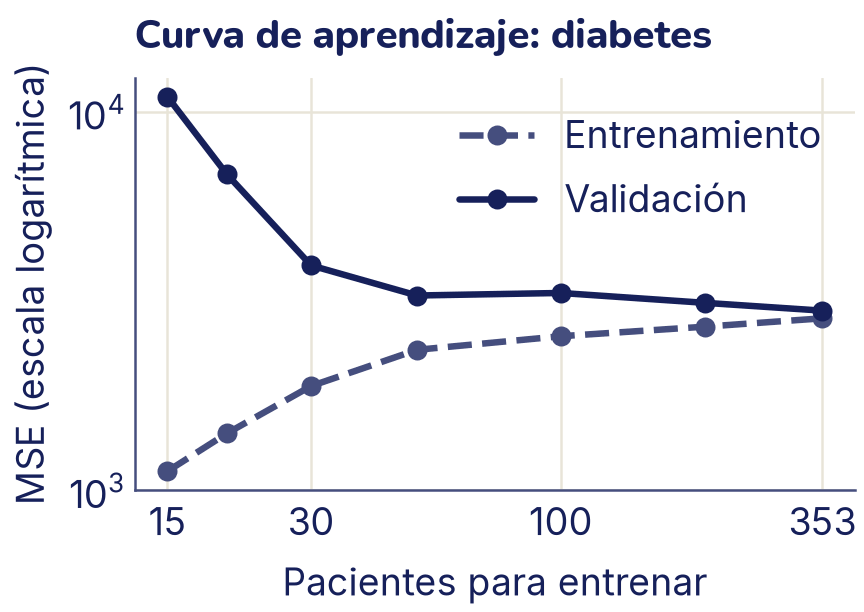

In [ ]:
from sklearn.model_selection import learning_curve

tamanos, p_ent, p_val = learning_curve(
    make_pipeline(StandardScaler(), LinearRegression()),
    diabetes.data, y_d, train_sizes=[15, 20, 30, 50, 100, 200, 353],
    cv=cinco, scoring="neg_mean_squared_error",
    shuffle=True, random_state=0)
mse_ent = -p_ent.mean(axis=1)         # promedio de los cinco pliegues
mse_val = -p_val.mean(axis=1)

for t, e, v in zip(tamanos, mse_ent, mse_val):
    print(f"{t:3d} pacientes:  entrenamiento {e:6.0f}"
          f"   validación {v:6.0f}")

# Entrenamiento a rayas, para distinguirlo de validación
plt.plot(tamanos, mse_ent, color="C2", marker="o", linestyle="--",
         label="Entrenamiento")
plt.plot(tamanos, mse_val, color="C0", marker="o", label="Validación")
plt.xscale("log")
plt.yscale("log")
# Marcas legibles en el eje x: solo algunos tamaños
plt.xticks([15, 30, 100, 353], ["15", "30", "100", "353"])
plt.minorticks_off()
plt.xlabel("Pacientes para entrenar")
plt.ylabel("MSE (escala logarítmica)")
plt.title("Curva de aprendizaje: diabetes")
plt.legend()
plt.show()

Con pocos pacientes, el modelo de 10 pesos se ajusta muy bien a los que ve y muy mal a los demás: varianza alta. A medida que hay más datos, memorizar se vuelve imposible: el error de entrenamiento sube, el de validación baja y las dos curvas se juntan. Así se lee la curva:

| Lo que ves | Diagnóstico | Qué probar |
|---|---|---|
| Las dos curvas altas y juntas | **Subajuste** (sesgo alto) | Un modelo más flexible o mejores características; más datos no ayudan |
| Entrenamiento bajo, validación mucho más alta, y la brecha se achica con más datos | **Sobreajuste** (varianza alta) | Más datos, regularizar o un modelo más simple |
| Las dos juntas y en un nivel aceptable | Buen ajuste | Nada; probar con la prueba |

En diabetes, al final las curvas casi se tocan: con 353 pacientes, un modelo lineal ya no sobreajusta, y conseguir más pacientes casi no lo mejoraría. Para bajar el error haría falta un modelo distinto o más información de cada paciente.

## La receta completa con diabetes

Juntemos todo y arreglemos la trampa del tema 6. Separamos un 25 % de los pacientes para la prueba, elegimos `alpha` de Ridge con validación cruzada **solo con el entrenamiento** y medimos con la prueba una sola vez. Como el `StandardScaler` va dentro del *pipeline*, la media y la desviación también se calculan solo con el entrenamiento: los pacientes de prueba no se miran para nada hasta el final.

In [ ]:
from sklearn.metrics import r2_score

Xd_ent, Xd_prueba, yd_ent, yd_prueba = train_test_split(
    diabetes.data, y_d, test_size=0.25, random_state=0)

# Como en el tema 6: entrenar y medir con los mismos pacientes
lineal = make_pipeline(StandardScaler(), LinearRegression())
lineal.fit(Xd_ent, yd_ent)
print(f"R² con los datos de entrenamiento: "
      f"{r2_score(yd_ent, lineal.predict(Xd_ent)):.3f}")

# Elegir alpha con validación cruzada, sin tocar la prueba
for alpha in [0.1, 1, 10, 100]:
    puntajes = cross_val_score(
        make_pipeline(StandardScaler(), Ridge(alpha=alpha)),
        Xd_ent, yd_ent, cv=cinco, scoring="r2")
    print(f"Ridge alpha = {alpha:5}:  R² de validación cruzada = "
          f"{puntajes.mean():.3f}")

R² con los datos de entrenamiento: 0.555
Ridge alpha =   0.1:  R² de validación cruzada = 0.522
Ridge alpha =     1:  R² de validación cruzada = 0.523
Ridge alpha =    10:  R² de validación cruzada = 0.523
Ridge alpha =   100:  R² de validación cruzada = 0.511


In [ ]:
# La prueba, una sola vez, con el modelo elegido
elegido = make_pipeline(StandardScaler(), Ridge(alpha=10))
elegido.fit(Xd_ent, yd_ent)
print(f"R² con los datos de prueba: "
      f"{r2_score(yd_prueba, elegido.predict(Xd_prueba)):.3f}")

R² con los datos de prueba: 0.358


`alpha` = 1 y `alpha` = 10 empatan en la validación cruzada; elegimos 10 porque, ante un empate, conviene el más regularizado: el modelo más simple. El R² medido con los pacientes de entrenamiento (0,555) era optimista. El de la prueba (0,358) salió más bajo incluso que el de la validación cruzada: 111 pacientes de prueba también traen su dosis de suerte, y en el ejercicio 6 vas a medir cuánto cambia con otra división. Aun así, es la única estimación que no participó en ninguna decisión, y por eso es la honesta. Fíjate también en que todas las `alpha` dan resultados parecidos: con 331 pacientes y solo 10 características, el modelo lineal casi no sobreajusta (lo dijo la curva de aprendizaje), así que regularizar ayuda poco. La regularización brilla cuando hay muchas características para pocos datos, como en el mini-proyecto.

Una última regla, la más importante del tema: **si después de mirar la prueba vuelves a cambiar el modelo, la prueba deja de ser nueva**. Su número ya no es honesto. Por eso se usa una sola vez, al final, y todas las decisiones se toman antes, con la validación.

## Lo que aprendiste y lo que sigue

- Un modelo sirve si **generaliza**: si acierta con datos que no vio. El error de entrenamiento no lo dice; puede bajar a casi cero mientras el modelo memoriza.
- Los datos se dividen en **entrenamiento** (ajustar), **validación** (elegir) y **prueba** (medir una sola vez, al final).
- El error de validación frente a la complejidad forma una **U**: a la izquierda, **subajuste** (sesgo alto); a la derecha, **sobreajuste** (varianza alta).
- La **validación cruzada k-fold** promedia *k* divisiones distintas, para no depender de la suerte de una sola.
- **Ridge** (L2) encoge todos los pesos; **Lasso** (L1) apaga algunos exactamente en cero, por las esquinas del rombo. Los dos piden características estandarizadas.
- La **curva de aprendizaje** dice si conseguir más datos ayudaría.

Todo esto vale para cualquier modelo que veas desde ahora: los clasificadores del tema 8, los árboles del tema 11 y las redes neuronales, que tienen tantos parámetros que sobreajustar es su riesgo principal (tema 19).

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `X_resto`, `y_resto`, `X_prueba`, `y_prueba`, `polinomio`, `nuevos_datos`, `cinco`, `X_d`, `y_d`, `nombres` y `diabetes`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. ¿Qué grupo usarías?

Para cada tarea, di si usarías los datos de **entrenamiento**, de **validación** o de **prueba**, y por qué.

1. Calcular los pesos de una regresión con `fit`.
2. Decidir entre un polinomio de grado 3 y uno de grado 5.
3. Elegir el `alpha` de Ridge.
4. Escribir en un informe cuánto se va a equivocar el modelo con casos nuevos.
5. Calcular la media y la desviación estándar para estandarizar las columnas.

<details>
<summary>Respuesta</summary>

1. **Entrenamiento**: es para lo único que existe.
2. **Validación** (o validación cruzada con los datos que no son de prueba): comparar modelos es una decisión.
3. **Validación**, por la misma razón: `alpha` es una perilla del modelo, como el grado.
4. **Prueba**, una sola vez y al final. Es el único grupo que no participó en ninguna decisión, así que es el único que da un número honesto.
5. **Entrenamiento**. Si la media y la desviación se calculan con todos los datos, información de la validación y de la prueba se cuela en el modelo. Por eso en la teoría el `StandardScaler` va dentro del *pipeline*: `fit` lo ajusta solo con los datos de entrenamiento.

</details>

### 2. Leer los errores

Imagina cuatro modelos entrenados con los mismos datos. Estos son sus errores (MSE); el ruido de los datos tiene un MSE de alrededor de 1. Di para cada uno si hay subajuste, sobreajuste o un buen ajuste.

| Modelo | Entrenamiento | Validación |
|---|---|---|
| A | 4,1 | 4,3 |
| B | 0,2 | 6,5 |
| C | 1,0 | 1,2 |
| D | 0,9 | 2,9 |

<details>
<summary>Respuesta</summary>

- **A, subajuste**: los dos errores son altos y parecidos, muy por encima del ruido. El modelo no capta ni los datos que ve. Hace falta un modelo más flexible.
- **B, sobreajuste fuerte**: el error de entrenamiento es mucho menor que el ruido (está memorizando el ruido) y el de validación es enorme. Hay que simplificar el modelo o regularizar.
- **C, buen ajuste**: los dos errores están cerca del ruido y cerca entre sí.
- **D, sobreajuste moderado**: el error de entrenamiento parece bueno, pero el de validación es más del triple. Conviene regularizar un poco o probar un modelo más simple.

</details>

### 3. Elegir el grado con validación cruzada

En la teoría, la validación cruzada con 5 pliegues eligió el grado 3. Repite la elección con 10 pliegues (`KFold(n_splits=10, shuffle=True, random_state=0)`) y con 5 pliegues pero otra semilla de mezcla (`random_state=1`). ¿Sale el mismo grado? ¿Cuántos modelos se entrenan en total con 10 pliegues y 15 grados?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def elegir_grado(cv):
    """El grado de 1 a 15 con menor MSE de validación cruzada."""
    errores = []
    for grado in range(1, 16):
        puntajes = cross_val_score(polinomio(grado), X_resto, y_resto,
                                   cv=cv, scoring="neg_mean_squared_error")
        errores.append(-puntajes.mean())
    mejor = int(np.argmin(errores)) + 1
    return mejor, min(errores)

for nombre, cv in [("10 pliegues        ", KFold(10, shuffle=True,
                                                random_state=0)),
                   ("5 pliegues, otra mezcla", KFold(5, shuffle=True,
                                                     random_state=1))]:
    grado, error = elegir_grado(cv)
    print(f"{nombre}:  grado {grado}   MSE {error:.3f}")

<details>
<summary>Respuesta</summary>

Con 10 pliegues se entrenan 10 modelos por grado: 150 modelos en total.

</details>

### 4. Encuentra el error

Una compañera quiere elegir el grado del polinomio y escribe esto:

In [ ]:
errores_prueba = []
for grado in range(1, 16):
    modelo = polinomio(grado).fit(X_resto, y_resto)
    errores_prueba.append(
        mean_squared_error(y_prueba, modelo.predict(X_prueba)))
grado_elegido = int(np.argmin(errores_prueba)) + 1
print(f"Grado elegido: {grado_elegido}   "
      f"MSE de prueba: {min(errores_prueba):.3f}")

Grado elegido: 6   MSE de prueba: 0.042


Y escribe en su informe: «con datos nuevos, el modelo tendrá un MSE de alrededor de 0,042». ¿Qué está mal?

Compruébalo con una simulación. Como fabricamos los datos, podemos repetir su procedimiento 100 veces, cada vez con 40 puntos nuevos (30 para entrenar y 10 de «prueba»), y medir cuánto se equivoca **de verdad** el modelo elegido con 2000 puntos que nadie usó. Compáralo con un procedimiento honesto: fijar el grado de antemano (el 3, que ya elegimos con validación cruzada) y medirlo con la prueba una sola vez.

<details>
<summary>Respuesta</summary>

Usó la prueba para **elegir** el grado. Al probar 15 modelos y quedarse con el que mejor le fue con esos 10 puntos, eligió en parte al que tuvo más suerte con ellos. El número que reporta ya no mide datos nuevos: es el mínimo de 15 intentos, y por eso es optimista.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
X_nuevos, y_nuevos = nuevos_datos(999, n=2000)
reportado, real = [], []              # eligiendo con la prueba
reportado_3, real_3 = [], []          # grado 3 fijo, prueba una vez
for semilla in range(100):
    X_n, y_n = nuevos_datos(1000 + semilla, n=40)
    X_a, X_b = X_n[:30], X_n[30:]     # 30 para entrenar, 10 de prueba
    y_a, y_b = y_n[:30], y_n[30:]
    modelos = [polinomio(g).fit(X_a, y_a) for g in range(1, 16)]
    errores = [mean_squared_error(y_b, m.predict(X_b)) for m in modelos]
    elegido = modelos[int(np.argmin(errores))]
    reportado.append(min(errores))
    real.append(mean_squared_error(y_nuevos, elegido.predict(X_nuevos)))
    reportado_3.append(errores[2])    # el grado 3 es el tercer modelo
    real_3.append(
        mean_squared_error(y_nuevos, modelos[2].predict(X_nuevos)))

for nombre, rep, rea in [("Eligiendo con la prueba", reportado, real),
                         ("Grado 3 fijo           ", reportado_3, real_3)]:
    print(f"{nombre}:  reportado {np.mean(rep):.3f}"
          f"   real {np.mean(rea):.3f}"
          f"   (medianas {np.median(rep):.3f} y {np.median(rea):.3f})")

<details>
<summary>Respuesta (sigue)</summary>

Eligiendo con la prueba, el número reportado promete un error de alrededor de 0,09, pero el error real es mucho mayor: a veces el grado que tuvo suerte con 10 puntos es uno muy alto que se dispara con datos nuevos, y esos casos suben muchísimo el promedio. Incluso la mediana, que no se deja llevar por esos casos, sale más alta que lo reportado. Con el grado fijado de antemano, lo reportado y lo real coinciden bastante: la prueba usada una sola vez no engaña en promedio.

La forma correcta es la de la teoría: elegir con validación (o validación cruzada) sin tocar la prueba, y usar la prueba una sola vez, con el modelo ya elegido.

</details>

### 5. Ridge contra Lasso

Con los datos de diabetes estandarizados de la teoría (`X_d`, `y_d`):

a) Entrena `Ridge(alpha=1000)` y `Lasso(alpha=5)`. Cuenta cuántos pesos de cada uno son exactamente cero y cuál es el peso más chico en valor absoluto.

b) Explica con el dibujo del rombo y el círculo por qué uno deja ceros y el otro no.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
ridge = Ridge(alpha=1000).fit(X_d, y_d)
lasso = Lasso(alpha=5).fit(X_d, y_d)
for nombre, m in [("Ridge", ridge), ("Lasso", lasso)]:
    print(f"{nombre}:  pesos en cero = {np.sum(m.coef_ == 0)}"
          f"   el más chico = {np.min(np.abs(m.coef_)):.4f}")

<details>
<summary>Respuesta</summary>

a) Ridge, aun con un castigo enorme, no deja ningún peso en cero: el más chico es diminuto, pero no es cero. Lasso, con un castigo moderado, deja varios exactamente en cero.

b) La región de Ridge es un círculo, sin esquinas: la elipse del MSE lo toca en un punto cualquiera del borde, donde los pesos son chicos pero no nulos. La región de Lasso es un rombo, con esquinas sobre los ejes que sobresalen, y la elipse suele tocarlo primero en una esquina o en una arista, donde uno o varios pesos valen cero.

</details>

### 6. La suerte de la división

En la teoría, el R² de prueba de diabetes salió 0,358 con `random_state=0`. Repite la división con las semillas 0 a 9 (mismo modelo: `StandardScaler` y `Ridge(alpha=10)`) y anota el R² de prueba de cada una. Después calcula el R² de validación cruzada con 5 pliegues usando todos los pacientes. ¿Qué conclusión sacas?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
r2s = []
for semilla in range(10):
    Xa, Xb, ya, yb = train_test_split(diabetes.data, y_d, test_size=0.25,
                                      random_state=semilla)
    m = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(Xa, ya)
    r2s.append(r2_score(yb, m.predict(Xb)))
print("R² de prueba:", np.round(r2s, 2))
print(f"de {min(r2s):.2f} a {max(r2s):.2f}")

cv_todos = cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=10)),
                           diabetes.data, y_d, cv=cinco, scoring="r2")
print(f"Validación cruzada: {np.round(cv_todos, 2)}"
      f"   promedio {cv_todos.mean():.3f}")

<details>
<summary>Respuesta</summary>

Con 111 pacientes de prueba, el R² cambia bastante según quiénes cayeron en la prueba: va de 0,36 a 0,60, y la semilla 0 fue justo la de peor suerte. Un solo número de prueba con pocos datos tiene un margen de error grande, y eso hay que decirlo al reportarlo. La validación cruzada promedia varias divisiones y da una idea de cuánto varía el resultado. Lo que **no** se vale es probar semillas hasta encontrar la que da el mejor número.

</details>

### 7. ¿Por qué escalar antes de regularizar?

Imagina que la columna `bmi` viniera en otra unidad, con números 100 veces más chicos (como pasar de centímetros a metros: la unidad es más grande y los números, más chicos). Para una regresión sin castigo da igual: el peso se multiplica por 100 y las predicciones no cambian. ¿Y para Ridge? Compara el peso de `bmi` y el R² de validación cruzada de `Ridge(alpha=10)` con las columnas estandarizadas y con `bmi` dividida por 100.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
X_mal = X_d.copy()
X_mal[:, 2] = X_mal[:, 2] / 100         # bmi en una unidad 100 veces mayor

for nombre, datos in [("estandarizado", X_d), ("bmi / 100    ", X_mal)]:
    m = Ridge(alpha=10).fit(datos, y_d)
    r2 = cross_val_score(Ridge(alpha=10), datos, y_d, cv=cinco,
                         scoring="r2").mean()
    # El efecto de bmi en las predicciones: peso por desviación de la columna
    efecto = m.coef_[2] * datos[:, 2].std()
    print(f"{nombre}:  efecto de bmi = {efecto:5.2f}   R² (CV) = {r2:.3f}")

<details>
<summary>Respuesta</summary>

Con `bmi` dividida por 100, para tener el mismo efecto el modelo necesitaría un peso 100 veces mayor, y Ridge castiga ese peso al cuadrado: le sale carísimo. El castigo prácticamente borra a `bmi`, la variable que más ayudaba, y el modelo empeora. Que una columna se castigue más que otra no debería depender de las unidades en que alguien la anotó: por eso se estandariza antes de regularizar.

</details>

### 8. Las viviendas, ahora con prueba

En el mini-proyecto del tema 6 mediste el modelo de las viviendas de California con los mismos datos de entrenamiento. Repítelo bien: separa un 20 % para prueba (`random_state=0`), entrena `LinearRegression` con las 8 columnas estandarizadas (en un *pipeline*) y compara el R² de entrenamiento con el de prueba. ¿Hay sobreajuste?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from sklearn.datasets import fetch_california_housing

casas = fetch_california_housing(as_frame=True)
Xc_ent, Xc_prueba, yc_ent, yc_prueba = train_test_split(
    casas.data, casas.target, test_size=0.2, random_state=0)
casas_lineal = make_pipeline(StandardScaler(), LinearRegression())
casas_lineal.fit(Xc_ent, yc_ent)
print(f"R² entrenamiento: "
      f"{r2_score(yc_ent, casas_lineal.predict(Xc_ent)):.3f}")
print(f"R² prueba:        "
      f"{r2_score(yc_prueba, casas_lineal.predict(Xc_prueba)):.3f}")

<details>
<summary>Respuesta</summary>

Los dos R² son casi iguales: con más de 16 000 zonas para entrenar y solo 8 pesos, una regresión lineal no tiene cómo memorizar. Su problema es el contrario, el **sesgo**: una función lineal de las 8 columnas es demasiado simple para los precios. Para mejorar haría falta un modelo más flexible (por ejemplo, los árboles del tema 11), no regularizar.

</details>

## Mini-proyecto: encontrar las 5 variables que importan

Vas a fabricar un problema donde **sabes la respuesta** y a comprobar si Lasso la encuentra. Hay 30 características, pero el objetivo depende solo de 5 de ellas; las otras 25 son puro ruido. Con pocos datos, una regresión común se confunde con tantas columnas inútiles.

In [ ]:
rng_p = np.random.default_rng(7)
n_p, d_p = 80, 30
X_p = rng_p.normal(size=(n_p, d_p))
# Solo 5 columnas importan; el resto de los pesos verdaderos son cero
w_verdad = np.zeros(d_p)
utiles = rng_p.choice(d_p, size=5, replace=False)
w_verdad[utiles] = rng_p.choice([-1, 1], size=5) * rng_p.uniform(1, 3, 5)
y_p = X_p @ w_verdad + rng_p.normal(0, 1.5, size=n_p)
print("Forma de X:", X_p.shape)

Forma de X: (80, 30)


No mires `utiles` ni `w_verdad` hasta el paso 5: hacen de «la verdad que nadie conoce».

**Pasos.**

1. **Separa** un 25 % de los datos para prueba (`random_state=0`).
2. **Regresión común.** Entrena `LinearRegression` y compara el R² de entrenamiento con el de prueba. ¿Hay sobreajuste? ¿Cuántos pesos son distintos de cero?
3. **Elige el castigo.** Para varios valores de `alpha` de Lasso (por ejemplo, `np.logspace(-3, 0, 13)`), calcula el R² de validación cruzada con 5 pliegues usando solo el entrenamiento. Dibuja el R² frente a `alpha` y elige el mejor.
4. **Entrena y mide.** Entrena Lasso con ese `alpha` y mide el R² de prueba, una sola vez. Lista las columnas con peso distinto de cero.
5. **Compara con la verdad.** Ahora sí, mira `utiles`. ¿Encontró Lasso las 5? ¿Se le coló alguna columna inútil? ¿Qué tan grandes son los pesos de las que se colaron?
6. **Concluye** en tres frases: qué pasó con la regresión común, qué hizo Lasso y por qué Ridge no te habría dicho cuáles variables importan.

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
Xp_ent, Xp_prueba, yp_ent, yp_prueba = train_test_split(
    X_p, y_p, test_size=0.25, random_state=0)

comun = LinearRegression().fit(Xp_ent, yp_ent)
print(f"Regresión común:  R² entrenamiento "
      f"{comun.score(Xp_ent, yp_ent):.3f}"
      f"   R² prueba {comun.score(Xp_prueba, yp_prueba):.3f}")

alphas_p = np.logspace(-3, 0, 13)
r2_cv = [cross_val_score(Lasso(alpha=a), Xp_ent, yp_ent, cv=cinco,
                         scoring="r2").mean() for a in alphas_p]
alpha_p = alphas_p[np.argmax(r2_cv)]
print(f"Mejor alpha por validación cruzada: {alpha_p:.3f}"
      f"   (R² de validación cruzada {max(r2_cv):.3f})")

lasso_p = Lasso(alpha=alpha_p).fit(Xp_ent, yp_ent)
print(f"Lasso:  R² prueba {lasso_p.score(Xp_prueba, yp_prueba):.3f}")
elegidas = np.flatnonzero(lasso_p.coef_)
print("Columnas que usa Lasso:", elegidas)
print("Columnas que importan: ", np.sort(utiles))
colados = [j for j in elegidas if j not in utiles]
print("Pesos de las columnas que se colaron:",
      np.round(lasso_p.coef_[colados], 2))
print("Pesos de las 5 que importan (Lasso / verdad):")
for j in np.sort(utiles):
    print(f"  columna {j:2d}:  {lasso_p.coef_[j]:5.2f} / {w_verdad[j]:5.2f}")

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

- La regresión común sobreajusta: con 60 datos para entrenar y 30 pesos, explica el 95 % de la variación con los datos que vio, pero baja a 0,81 con la prueba.
- Lasso, con `alpha` elegido por validación cruzada, mejora la prueba a 0,88 y encuentra las 5 columnas que importan, con pesos cercanos a los verdaderos (casi todos algo más chicos: el castigo los encoge).
- Se le colaron 7 columnas inútiles, todas con pesos chicos (ninguno pasa de 0,25 en valor absoluto, contra más de 1,3 de las útiles). Con un `alpha` un poco mayor se apagarían, a costa de encoger más las útiles.
- Ridge encoge los pesos, pero los deja a los 30 distintos de cero: no te diría cuáles variables importan.

</details>

## Errores comunes

- **Medir con los datos de entrenamiento.** El error de entrenamiento siempre es optimista y no dice nada sobre datos nuevos. Mide siempre con datos que el modelo no vio.
- **Elegir mirando la prueba.** Si eliges el grado, `alpha` o las variables según el resultado de prueba, ese resultado deja de ser honesto. Elige con validación y usa la prueba una sola vez.
- **Estandarizar antes de dividir.** Si calculas la media y la desviación con todos los datos, información de la prueba se cuela en el entrenamiento. Pon el `StandardScaler` dentro de un *pipeline*.
- **Regularizar sin estandarizar.** El castigo trata a todos los pesos por igual; si las columnas tienen escalas distintas, castiga más a unas que a otras sin ninguna razón.
- **Olvidar el signo en scikit-learn.** `cross_val_score` con `"neg_mean_squared_error"` devuelve el MSE con signo negativo. Cámbiale el signo antes de elegir el mínimo, o elegirás el peor modelo.
- **Usar `KFold` sin mezclar con datos ordenados.** Si los datos vienen ordenados (por fecha, por región, por clase), los pliegues sin `shuffle=True` son grupos raros y la validación sale engañosa. (Con datos en el tiempo hay que hacer otra cosa; lo verás en el tema 13.)
- **Creer que más datos siempre ayudan.** Si las dos curvas de aprendizaje ya están juntas y altas, el problema es el sesgo: hace falta un modelo mejor, no más datos.
- **Probar semillas hasta que el número salga bonito.** La semilla de `train_test_split` se fija antes de mirar los resultados, no después.
- **Leer los ceros de Lasso como «esta variable no tiene relación».** Si dos variables dicen casi lo mismo, Lasso suele quedarse con una y apagar la otra, aunque las dos estén relacionadas con el objetivo.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Dividir los datos en entrenamiento, validación y prueba, y explicar para qué sirve cada parte (ejercicios 1 y 4, y paso 1 del mini-proyecto).
- Reconocer el subajuste y el sobreajuste en curvas de error (ejercicios 2 y 8, y paso 2 del mini-proyecto).
- Aplicar validación cruzada k-fold (ejercicios 3 y 6, y paso 3 del mini-proyecto).
- Usar Ridge y Lasso y explicar por qué Lasso deja coeficientes en cero (ejercicios 5 y 7, y pasos 4 y 5 del mini-proyecto).